In [2]:
from pathlib import Path
TACO_DIR = Path("../datasets/TACO/data/taco_yolo").resolve()

TACO_DIR.exists()

True

In [ ]:
import json
from collections import Counter

meta = json.loads((TACO_DIR.parent / "annotations.json").read_text(encoding="utf-8"))

In [18]:
counts = {}

for split in ("train", "val"):
  counts[split] = Counter()

  for label_path in (TACO_DIR / "labels" / split).glob("*.txt"):
    for line in label_path.read_text(encoding="utf-8").splitlines():
      if line.strip():
        class_id = int(line.split()[0])
        counts[split][class_id] += 1

print(f"{"클래스":29} {"train":>5} {"val":>6} {"val 비율":>9}")
for category in meta["categories"]:
  class_id = category["id"]
  train = counts["train"][class_id]
  val = counts["val"][class_id]
  ratio = val / (train + val) if train + val else 0
  print(f"{category["name"][:30]:30} {train:>6} {val:>6} {ratio:>10.1%} {category["name"] + " 없음" if val == 0 else "":>25}")

클래스                           train    val    val 비율
Aluminium foil                     53      9      14.5%                          
Battery                             2      0       0.0%                Battery 없음
Aluminium blister pack              5      1      16.7%                          
Carded blister pack                 1      0       0.0%    Carded blister pack 없음
Other plastic bottle               37     13      26.0%                          
Clear plastic bottle              220     65      22.8%                          
Glass bottle                       88     16      15.4%                          
Plastic bottle cap                165     44      21.1%                          
Metal bottle cap                   59     21      26.2%                          
Broken glass                      127     11       8.0%                          
Food Can                           27      7      20.6%                          
Aerosol                             7      3 

In [34]:
len(list(counts["val"].keys() | counts["train"].keys()))

59

# val에 없거나 적은 클래스
없는 클래스: Battery, Carded blister pack, Other plasit cup, Plastified paper bag

In [21]:
meta["categories"][0], len(meta["categories"])

({'supercategory': 'Aluminium foil', 'id': 0, 'name': 'Aluminium foil'}, 60)

In [45]:
sup_counts = {}
printed = set()

# split별로 sup_conuts 추가해주기.
for split in ("train", "val"):
  sup_counts[split] = Counter()

  # 모든 supercategory에 대해 순회
  for super_cat in list(map(lambda x: x["supercategory"], meta["categories"])):
    # if split == "train" and super_cat not in printed:
    #   printed.add(super_cat)
      
    # train과 val에 대해서 supercategory: 개수 로 만들어주기
    sup_counts[split][super_cat] = sum([counts[split][c["id"]] for c in list(filter(lambda x: x["supercategory"] == super_cat, meta["categories"]))])

for super_cat in list(map(lambda x: x["supercategory"], meta["categories"])):
    if super_cat not in printed:
      printed.add(super_cat)
      print(f"{super_cat}: {list(map(lambda x: x["name"], filter(lambda x: x["supercategory"] == super_cat, meta["categories"])))}")
      print(sup_counts["train"][super_cat], sup_counts["val"][super_cat])

Aluminium foil: ['Aluminium foil']
53 9
Battery: ['Battery']
2 0
Blister pack: ['Aluminium blister pack', 'Carded blister pack']
6 1
Bottle: ['Other plastic bottle', 'Clear plastic bottle', 'Glass bottle']
345 94
Bottle cap: ['Plastic bottle cap', 'Metal bottle cap']
224 65
Broken glass: ['Broken glass']
127 11
Can: ['Food Can', 'Aerosol', 'Drink can']
203 70
Carton: ['Toilet tube', 'Other carton', 'Egg carton', 'Drink carton', 'Corrugated carton', 'Meal carton', 'Pizza box']
206 45
Cup: ['Paper cup', 'Disposable plastic cup', 'Foam cup', 'Glass cup', 'Other plastic cup']
150 42
Food waste: ['Food waste']
7 1
Glass jar: ['Glass jar']
5 1
Lid: ['Plastic lid', 'Metal lid']
72 15
Other plastic: ['Other plastic']
209 64
Paper: ['Magazine paper', 'Tissues', 'Wrapping paper', 'Normal paper']
121 27
Paper bag: ['Paper bag', 'Plastified paper bag']
19 8
Plastic bag & wrapper: ['Plastic film', 'Six pack rings', 'Garbage bag', 'Other plastic wrapper', 'Single-use carrier bag', 'Polypropylene bag

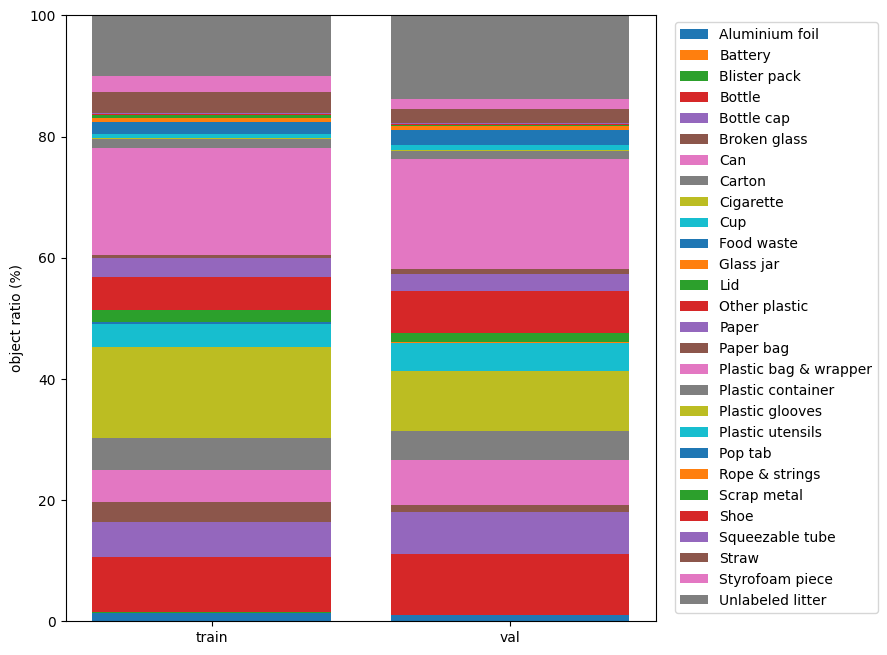

In [47]:
import matplotlib.pyplot as plt

splits = ("train", "val")
supercategories = sorted(
    {c["supercategory"] for c in meta["categories"]}
)
bottom = [0, 0]

plt.figure(figsize=(9, 7))

for supercategory in supercategories:
    heights = [
        sup_counts[split][supercategory] / sum(sup_counts[split].values()) * 100
        for split in splits
    ]
    plt.bar(splits, heights, bottom=bottom, label=supercategory)
    bottom = [bottom[i] + heights[i] for i in range(2)]

plt.ylabel("object ratio (%)")
plt.ylim(0, 100)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

In [49]:
model.train(data=str(TACO_DIR / "data.yaml"), device=[0])

New https://pypi.org/project/ultralytics/8.4.207 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.143  Python-3.12.10 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti Laptop GPU, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\LANG_CHAIN_2026\final-project\parkkeeper-jupjup\members\hur-wan\datasets\TACO\data\taco_yolo\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  2,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18,
       19, 20, 21, 22, 23, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 36, 37,
       38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54,
       55, 56, 57, 58, 59])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000016841B21250>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([0.        , 0.001001  , 0.002002  , 0.003003  , 0.004004  ,
       0.00500501, 0.00600601, 0.00700701, 0.00800801, 0.00900901,
       0.01001001, 0.01101101, 0.01201201, 0.01301301, 0.01401401,
       0.01501502, 0.01601602, 0.01701702, 0.01801802, 0.01901902,
       0.02002002, 0.02102102, 0.02202202, 0.02302302, 0.02402402,
       0.02502503, 0.02602603, 0.02702703, 0.02802803, 0.02902903,
       0.0